# WLF7 Hands-on Workshop: XGBoost for Pore-Water Pressure Forecasting

**Research basis:** Amos Silungwe & Hemalatha T., *Downslope and Upslope Location Effects on Multi-Horizon Pore-Water Pressure Prediction for Landslide Monitoring*.

**Workshop level:** Intermediate  
**Focus:** Reproduce the original XGBoost workflow, audit its time axis, then build Explainable AI workflow.

## Learning outcomes
By the end of the practical, participants should be able to:
1. inspect and prepare multivariate hillslope monitoring data;
2. construct sliding windows and flatten them for tree-based learning;
3. train separate XGBoost regressors for downslope PP1 and upslope PP2;
4. evaluate forecasts using RMSE and compare with persistence;
5. interpret feature importance and discuss limitations for early warning.

> **Important reproducibility note:** The uploaded notebook builds windows from `df_full`, which contains 7,488 five-minute records. With `L=48`, the input covers 4 hours; with `H=12`, the target sequence covers 1 hour. Its selected indices `[0, 3, 6, 11]` therefore correspond to the first through twelfth five-minute target samples (approximately 5, 20, 35 and 60 minutes after the input window). The manuscript reports those labels as hours. This practical preserves the original five-minute implementation as an **audit/reproduction track**, and separately constructs a genuine hourly track for 1, 4, 7 and 12-hour forecasts.

## Data required
Upload the original USGS BALT2 CSV (`USGS_BALT2_csv.csv`). The CSV itself was not included with the uploaded notebook, so model training cannot be executed until participants provide it.


## 0. Environment and imports

In [1]:
# If needed in Google Colab, uncomment:
# %pip install -q xgboost shap

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore")

print("pandas:", pd.__version__)
import xgboost
print("XGBoost:", xgboost.__version__)


pandas: 2.2.3
XGBoost: 3.4.1


## 1. Upload and inspect the source data

In [2]:
# Google Colab upload:
from google.colab import files
uploaded = files.upload()
csv_path = next(iter(uploaded))

# If running locally, replace the two lines above with:
# csv_path = "USGS_BALT2_csv.csv"

raw = pd.read_csv(csv_path)
print("Raw shape:", raw.shape)
display(raw.head())
print("\\nColumns:")
for c in raw.columns:
    print("-", c)


Saving USGS_BALT2_csv.csv to USGS_BALT2_csv.csv
Raw shape: (7488, 9)


,"Date and time (MM/DD/YYYY hh:mm, PST)","SM1 (downslope nest, 55 cm) (m^3/m^3)","SM2 (downslope nest, 25 cm) (m^3/m^3)","SM3 (upslope nest, 100 cm) (m^3/m^3)","SM4 (upslope nest, 55 cm) (m^3/m^3)","SM5 (upslope nest, 25 cm) (m^3/m^3)","PP1 (downslope nest, 113 cm) (cm H2O)","PP2 (upslope nest, 118 cm) (cm H2O)",Rain (mm)
0,12/25/2022 0:00,0.291,0.194,0.287,0.252,0.249,-0.615,-2.608,0.0
1,12/25/2022 0:05,0.291,0.194,0.287,0.253,0.249,-0.621,-2.601,0.0
2,12/25/2022 0:10,0.291,0.194,0.287,0.252,0.249,-0.594,-2.586,0.0
3,12/25/2022 0:15,0.291,0.194,0.287,0.253,0.249,-0.605,-2.601,0.0
4,12/25/2022 0:20,0.291,0.194,0.287,0.253,0.249,-0.609,-2.579,0.0


\nColumns:
- Date and time (MM/DD/YYYY hh:mm, PST)
- SM1 (downslope nest, 55 cm) (m^3/m^3)
- SM2 (downslope nest, 25 cm) (m^3/m^3)
- SM3 (upslope nest, 100 cm) (m^3/m^3)
- SM4 (upslope nest, 55 cm) (m^3/m^3)
- SM5 (upslope nest, 25 cm) (m^3/m^3)
- PP1 (downslope nest, 113 cm) (cm H2O)
- PP2 (upslope nest, 118 cm) (cm H2O)
- Rain (mm)


###1a — Soil Moisture Missing Data Audit

Soil moisture sensors identified:
- SM1 (downslope nest, 55 cm) (m^3/m^3)
- SM2 (downslope nest, 25 cm) (m^3/m^3)
- SM3 (upslope nest, 100 cm) (m^3/m^3)
- SM4 (upslope nest, 55 cm) (m^3/m^3)
- SM5 (upslope nest, 25 cm) (m^3/m^3)

SOIL MOISTURE MISSING-DATA AUDIT


,Sensor,Total_Observations,Missing_Values,Available_Values,Missing_Percentage,Available_Percentage
0,"SM1 (downslope nest, 55 cm) (m^3/m^3)",7488,0,7488,0.00,100.00
1,"SM2 (downslope nest, 25 cm) (m^3/m^3)",7488,0,7488,0.00,100.00
2,"SM3 (upslope nest, 100 cm) (m^3/m^3)",7488,4423,3065,59.07,40.93
3,"SM4 (upslope nest, 55 cm) (m^3/m^3)",7488,912,6576,12.18,87.82
4,"SM5 (upslope nest, 25 cm) (m^3/m^3)",7488,562,6926,7.51,92.49



SM3 MISSING-DATA SUMMARY
Total observations: 7488
Missing observations: 4423
Available observations: 3065
Missing percentage: 59.07%


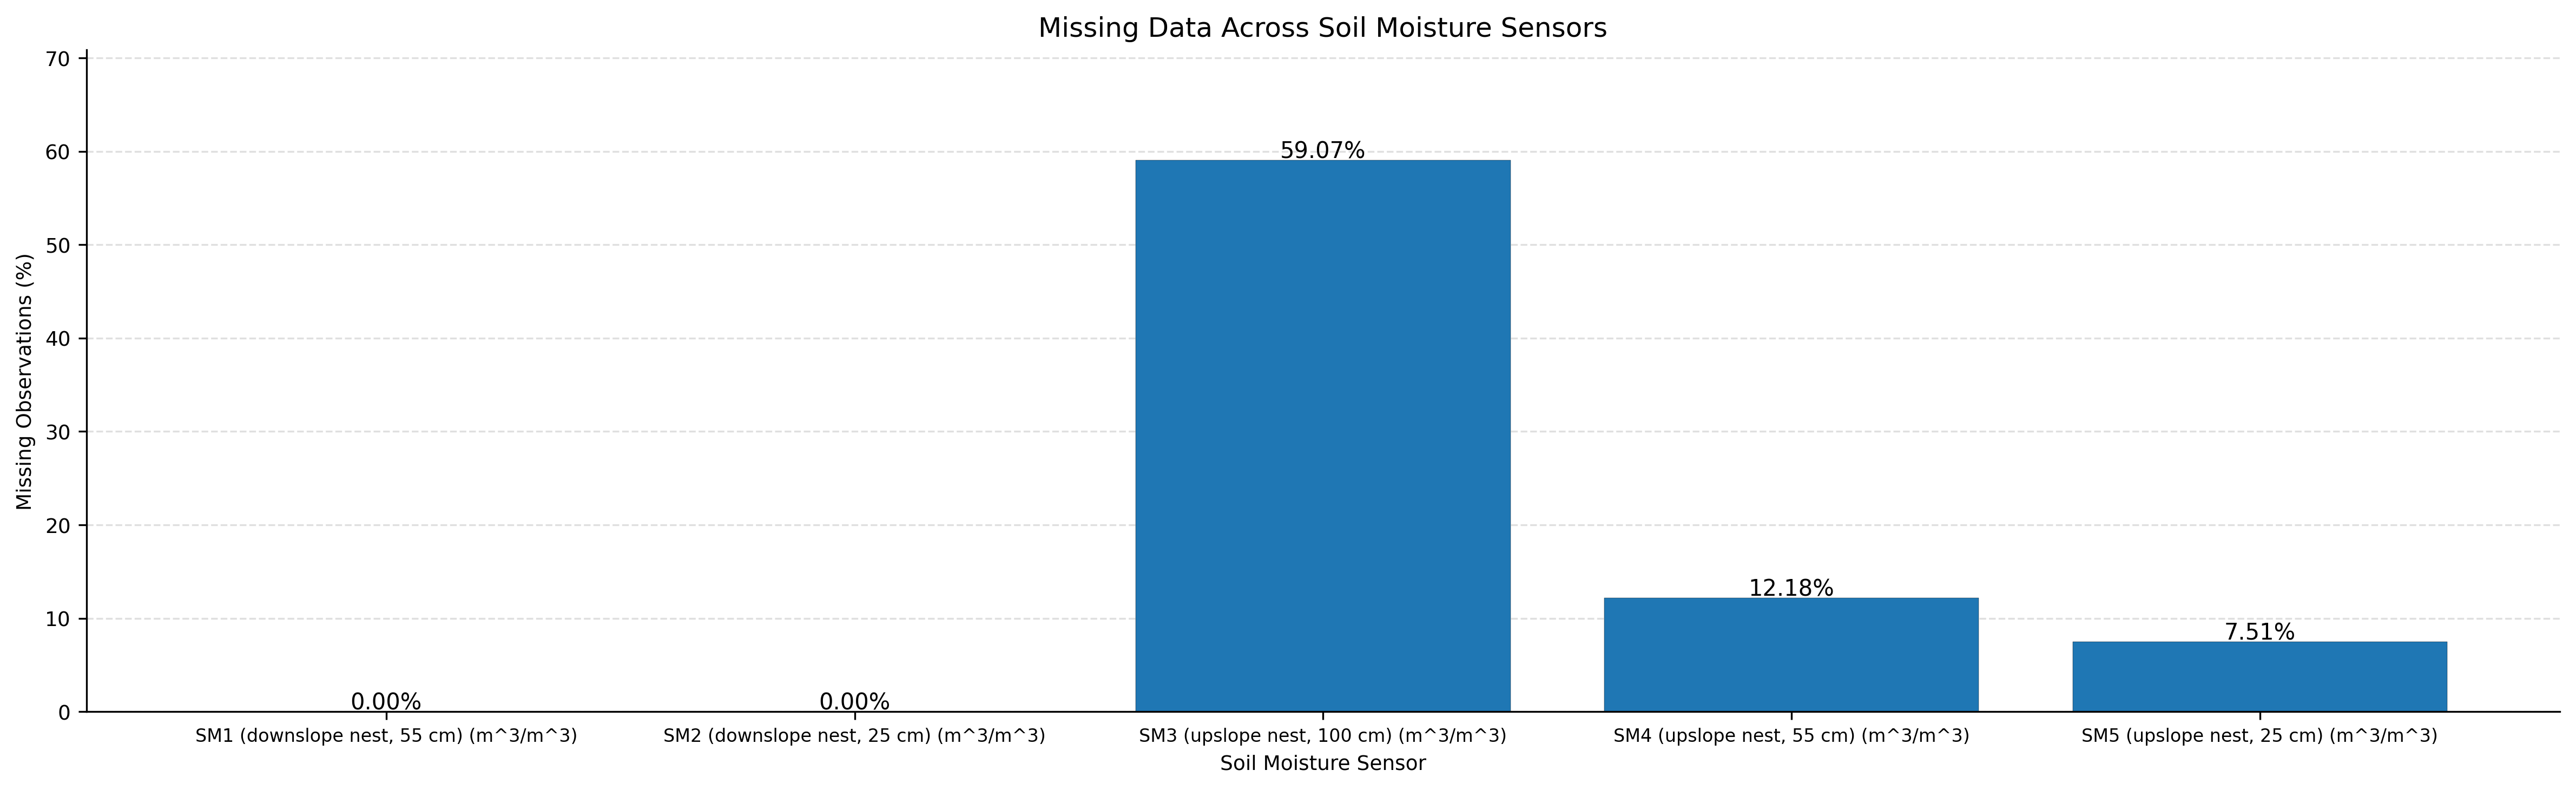


SENSOR DATA AVAILABILITY
SM1 (downslope nest, 55 cm) (m^3/m^3): No missing observations
SM2 (downslope nest, 25 cm) (m^3/m^3): No missing observations
SM3 (upslope nest, 100 cm) (m^3/m^3): Partially missing
SM4 (upslope nest, 55 cm) (m^3/m^3): Partially missing
SM5 (upslope nest, 25 cm) (m^3/m^3): Partially missing


In [25]:

# ============================================================
# STAGE 1A — SOIL MOISTURE MISSING-DATA AUDIT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Identify soil-moisture columns
# ------------------------------------------------------------

sm_columns = [
    col for col in raw.columns
    if col.strip().upper().startswith("SM")
]

print("Soil moisture sensors identified:")
for col in sm_columns:
    print("-", col)

# ------------------------------------------------------------
# 2. Calculate missing-data statistics
# ------------------------------------------------------------

sm_audit = pd.DataFrame({
    "Sensor": sm_columns,
    "Total_Observations": [len(raw)] * len(sm_columns),
    "Missing_Values": [raw[col].isna().sum() for col in sm_columns],
    "Available_Values": [raw[col].notna().sum() for col in sm_columns],
    "Missing_Percentage": [
        raw[col].isna().mean() * 100 for col in sm_columns
    ],
    "Available_Percentage": [
        raw[col].notna().mean() * 100 for col in sm_columns
    ]
})

sm_audit["Missing_Percentage"] = sm_audit["Missing_Percentage"].round(2)
sm_audit["Available_Percentage"] = sm_audit["Available_Percentage"].round(2)

print("\nSOIL MOISTURE MISSING-DATA AUDIT")
display(sm_audit)

# ------------------------------------------------------------
# 3. Identify the missing-data status of SM3
# ------------------------------------------------------------

sm3_col = next(
    (col for col in sm_columns if col.strip().upper().startswith("SM3")),
    None
)

if sm3_col is not None:

    sm3_missing = raw[sm3_col].isna().sum()
    sm3_available = raw[sm3_col].notna().sum()
    sm3_percentage = raw[sm3_col].isna().mean() * 100

    print("\nSM3 MISSING-DATA SUMMARY")
    print("Total observations:", len(raw))
    print("Missing observations:", sm3_missing)
    print("Available observations:", sm3_available)
    print(f"Missing percentage: {sm3_percentage:.2f}%")

else:
    print("\nWARNING: SM3 column was not found.")

# ------------------------------------------------------------
# 4. Visualise missing-data percentages
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 5))

bars = ax.bar(
    sm_audit["Sensor"],
    sm_audit["Missing_Percentage"],
    edgecolor="black",
    linewidth=0.1
)

ax.set_title("Missing Data Across Soil Moisture Sensors")
ax.set_xlabel("Soil Moisture Sensor")
ax.set_ylabel("Missing Observations (%)")

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar, value in zip(bars, sm_audit["Missing_Percentage"]):
    ax.annotate(
        f"{value:.2f}%",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 1),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_ylim(0, max(5, sm_audit["Missing_Percentage"].max() * 1.2))

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Check whether any sensor has completely missing values
# ------------------------------------------------------------

print("\nSENSOR DATA AVAILABILITY")

for _, row in sm_audit.iterrows():

    if row["Missing_Percentage"] == 100:
        status = "Completely missing"

    elif row["Missing_Percentage"] == 0:
        status = "No missing observations"

    else:
        status = "Partially missing"

    print(f'{row["Sensor"]}: {status}')


## 2. Prepare the five-minute monitoring table

In [3]:
TIME_COL = "Date and time (MM/DD/YYYY hh:mm, PST)"
RAIN_COL = "Rain (mm)"
SM1_COL = "SM1 (downslope nest, 55 cm) (m^3/m^3)"
SM2_COL = "SM2 (downslope nest, 25 cm) (m^3/m^3)"
SM3_COL = "SM3 (upslope nest, 100 cm) (m^3/m^3)"
SM4_COL = "SM4 (upslope nest, 55 cm) (m^3/m^3)"
SM5_COL = "SM5 (upslope nest, 25 cm) (m^3/m^3)"
PP1_RAW = "PP1 (downslope nest, 113 cm) (cm H2O)"
PP2_RAW = "PP2 (upslope nest, 118 cm) (cm H2O)"

required = [TIME_COL, RAIN_COL, SM1_COL, SM2_COL, SM4_COL, SM5_COL, PP1_RAW, PP2_RAW]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError("Expected columns not found. Check CSV headers: " + str(missing_cols))

df5 = raw.copy()
df5[TIME_COL] = pd.to_datetime(df5[TIME_COL], format="mixed", errors="coerce")
df5 = df5.dropna(subset=[TIME_COL]).sort_values(TIME_COL)
# Source timestamps are PST in the dataset; keep the source clock as provided for interval auditing.
df5 = df5.set_index(TIME_COL)
df5 = df5[~df5.index.duplicated(keep="first")].copy()

# Match the research notebook: remove SM3 and convert pore pressure from cm H2O to m H2O.
df5 = df5.drop(columns=[SM3_COL], errors="ignore")
df5["rain"] = pd.to_numeric(df5[RAIN_COL], errors="coerce")
df5["PP1"] = pd.to_numeric(df5[PP1_RAW], errors="coerce") / 100.0
df5["PP2"] = pd.to_numeric(df5[PP2_RAW], errors="coerce") / 100.0

FEATURES = ["rain", SM1_COL, SM2_COL, SM4_COL, SM5_COL, "PP1", "PP2"]
for c in FEATURES:
    df5[c] = pd.to_numeric(df5[c], errors="coerce")

print("Five-minute table shape:", df5[FEATURES].shape)
print("Observed time intervals:")
print(df5.index.to_series().diff().value_counts().head(10))
display(df5[FEATURES].isna().sum().to_frame("missing values"))


Five-minute table shape: (7488, 7)
Observed time intervals:
Date and time (MM/DD/YYYY hh:mm, PST)
0 days 00:05:00    7487
Name: count, dtype: int64


,missing values
rain,0
"SM1 (downslope nest, 55 cm) (m^3/m^3)",0
"SM2 (downslope nest, 25 cm) (m^3/m^3)",0
"SM4 (upslope nest, 55 cm) (m^3/m^3)",912
"SM5 (upslope nest, 25 cm) (m^3/m^3)",562
PP1,0
PP2,0


### Missing-data treatment: make the decision visible

In [4]:
# The original notebook interpolates remaining variables across the full record.
# For a workshop reproduction, show the missingness before choosing a treatment.
missing_before = df5[FEATURES].isna().sum()
display(missing_before.to_frame("missing_before"))

# Reproduce the notebook's linear interpolation for the retained variables.
# CAUTION: interpolation across long outages can create artificial smoothness.
df5_model = df5[FEATURES].interpolate(method="linear", limit_direction="both")
print("Missing after interpolation:", int(df5_model.isna().sum().sum()))
print("Rows retained:", len(df5_model))


,missing_before
rain,0
"SM1 (downslope nest, 55 cm) (m^3/m^3)",0
"SM2 (downslope nest, 25 cm) (m^3/m^3)",0
"SM4 (upslope nest, 55 cm) (m^3/m^3)",912
"SM5 (upslope nest, 25 cm) (m^3/m^3)",562
PP1,0
PP2,0


Missing after interpolation: 0
Rows retained: 7488


## 3. Explore the hydrological signals

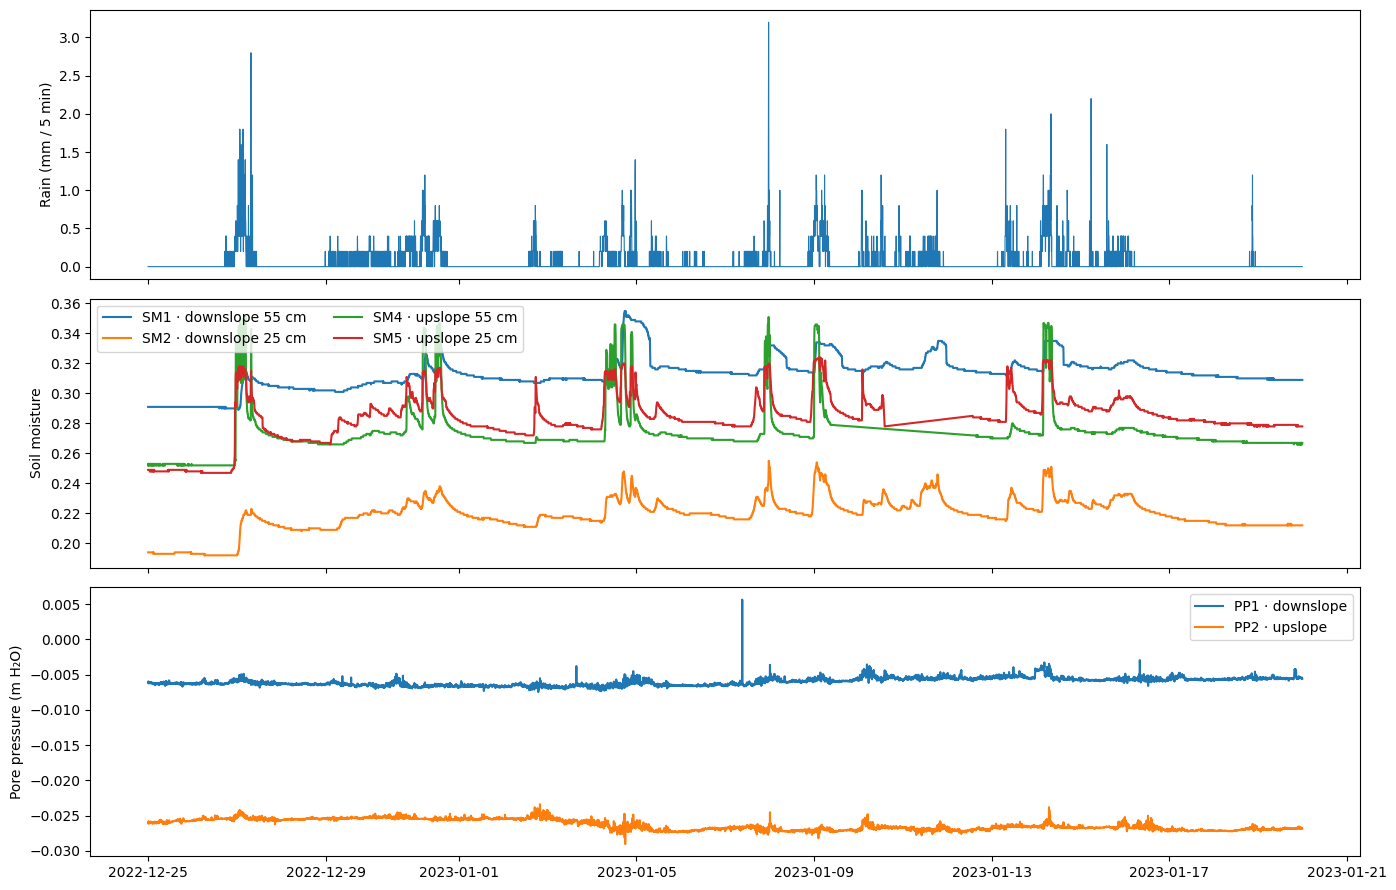

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(df5_model.index, df5_model["rain"], lw=0.8)
axes[0].set_ylabel("Rain (mm / 5 min)")
axes[1].plot(df5_model.index, df5_model[SM1_COL], label="SM1 · downslope 55 cm")
axes[1].plot(df5_model.index, df5_model[SM2_COL], label="SM2 · downslope 25 cm")
axes[1].plot(df5_model.index, df5_model[SM4_COL], label="SM4 · upslope 55 cm")
axes[1].plot(df5_model.index, df5_model[SM5_COL], label="SM5 · upslope 25 cm")
axes[1].set_ylabel("Soil moisture")
axes[1].legend(ncol=2)
axes[2].plot(df5_model.index, df5_model["PP1"], label="PP1 · downslope")
axes[2].plot(df5_model.index, df5_model["PP2"], label="PP2 · upslope")
axes[2].set_ylabel("Pore pressure (m H₂O)")
axes[2].legend()
plt.tight_layout()
plt.savefig("hydrological_signals.png", bbox_inches="tight")
plt.show()

## 4A. Track A — audit and reproduce the original five-minute window design

The code uses `L=48`, `H=12`, `stride=2`, then selects target indices `[0, 3, 6, 11]`. At five-minute sampling, this is a 4-hour input history and forecast targets at approximately 5, 20, 35 and 60 minutes after the input window ends.


In [6]:
L5, H5, STRIDE5 = 48, 12, 2
X5_list, Y5_list, t5_list = [], [], []

arr5 = df5_model[FEATURES].to_numpy(dtype=float)
for t in range(L5, len(df5_model) - H5 + 1, STRIDE5):
    X5_list.append(arr5[t-L5:t, :])
    Y5_list.append(np.column_stack([
        arr5[t:t+H5, FEATURES.index("PP1")],
        arr5[t:t+H5, FEATURES.index("PP2")]
    ]))
    t5_list.append(df5_model.index[t:t+H5])

X5 = np.asarray(X5_list)
Y5 = np.asarray(Y5_list)
print("X5:", X5.shape, "  Y5:", Y5.shape)
print("One window:", X5[0].shape, "One target sequence:", Y5[0].shape)

# Verify temporal meaning of selected target indices.
selected_5m = [0, 3, 6, 11]
for j in selected_5m:
    print(f"Y index {j}: target timestamp offset ≈ {(j+1)*5} minutes after last input timestamp")


X5: (3715, 48, 7)   Y5: (3715, 12, 2)
One window: (48, 7) One target sequence: (12, 2)
Y index 0: target timestamp offset ≈ 5 minutes after last input timestamp
Y index 3: target timestamp offset ≈ 20 minutes after last input timestamp
Y index 6: target timestamp offset ≈ 35 minutes after last input timestamp
Y index 11: target timestamp offset ≈ 60 minutes after last input timestamp


### Flatten the sequence into a tabular feature matrix

In [7]:
n5, lags5, nfeat5 = X5.shape
X5_tab = X5.reshape(n5, lags5 * nfeat5)
print("Flattened shape:", X5_tab.shape, f"= {lags5} lags × {nfeat5} variables")
print("Expected features per sample:", L5 * len(FEATURES))


Flattened shape: (3715, 336) = 48 lags × 7 variables
Expected features per sample: 336


###Targets:

In [8]:
# Predict first horizon (t+1)
y_pp1 = Y5[:,0,0]
y_pp2 = Y5[:,0,1]

print(y_pp1.shape, y_pp2.shape)

(3715,) (3715,)


###XGBoost PIPELINE

In [9]:
# =====================================================
# STEP 4: CONVERT SLIDING WINDOWS → TABULAR FEATURES
# =====================================================

import numpy as np

# Flatten lag window
n_samples = X5.shape[0]
n_lags = X5.shape[1]
n_features = X5.shape[2]

X_tab = X5.reshape(n_samples, n_lags * n_features)

print("X_tab shape:", X_tab.shape)

X_tab shape: (3715, 336)


###Train/Test Split (Time Series Safe)

In [10]:
# =====================================================
# STEP 5: TIME SERIES SPLIT (80/10/10)
# =====================================================

n = len(X_tab)

train_end = int(n * 0.8)
val_end   = int(n * 0.9)

# Features
X_train = X_tab[:train_end]
X_val   = X_tab[train_end:val_end]
X_test  = X_tab[val_end:]

# Targets PP1
y1_train = y_pp1[:train_end]
y1_val   = y_pp1[train_end:val_end]
y1_test  = y_pp1[val_end:]

# Targets PP2
y2_train = y_pp2[:train_end]
y2_val   = y_pp2[train_end:val_end]
y2_test  = y_pp2[val_end:]

print("Train set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Train set: (2972, 336)
Validation set: (371, 336)
Test set: (372, 336)


###Evaluation Metrics

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluate(obs, pred, label):

    rmse = np.sqrt(mean_squared_error(obs, pred))
    mae = mean_absolute_error(obs, pred)
    r2 = r2_score(obs, pred)

    print(f"\n{label}")
    print("RMSE:", rmse)
    print("MAE :", mae)
    print("R²  :", r2)

###Define Lead Times

In [12]:
lead_times = {
    "1h": 0,
    "4h": 3,
    "7h": 6,
    "12h": 11
}

###Train Models

In [13]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

results = []
xgb_models = {} # Initialize dictionary to store XGBoost models

for label, horizon in lead_times.items():

    print(f"\nTraining model for {label} lead time")

    # Targets
    y1_train = Y5[:train_end, horizon, 0]
    y1_val   = Y5[train_end:val_end, horizon, 0]
    y1_test  = Y5[val_end:, horizon, 0]

    y2_train = Y5[:train_end, horizon, 1]
    y2_val   = Y5[train_end:val_end, horizon, 1]
    y2_test  = Y5[val_end:, horizon, 1]

    # Model
    model_pp1 = XGBRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="rmse",
        early_stopping_rounds=50,
        random_state=42
    )

    model_pp2 = XGBRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="rmse",
        early_stopping_rounds=50,
        random_state=42
    )

    # Train
    model_pp1.fit(X_train, y1_train, eval_set=[(X_val, y1_val)], verbose=False)
    model_pp2.fit(X_train, y2_train, eval_set=[(X_val, y2_val)], verbose=False)

    # Store models for later plotting
    xgb_models[label] = {"model_pp1": model_pp1, "model_pp2": model_pp2}

    # Predict
    pred1 = model_pp1.predict(X_test)
    pred2 = model_pp2.predict(X_test)

    # Metrics
    rmse1 = np.sqrt(mean_squared_error(y1_test, pred1))
    rmse2 = np.sqrt(mean_squared_error(y2_test, pred2))

    r21 = r2_score(y1_test, pred1)
    r22 = r2_score(y2_test, pred2)

    results.append([label, rmse1, rmse2, r21, r22])


Training model for 1h lead time

Training model for 4h lead time

Training model for 7h lead time

Training model for 12h lead time


###Create Results Table

In [14]:
import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=["Lead Time", "RMSE_PP1", "RMSE_PP2", "R2_PP1", "R2_PP2"]
)

print(results_df)

  Lead Time  RMSE_PP1  RMSE_PP2    R2_PP1    R2_PP2
0        1h  0.000133  0.000077  0.634568  0.749828
1        4h  0.000165  0.000102  0.431641  0.594837
2        7h  0.000205  0.000102  0.123929  0.561495
3       12h  0.000209  0.000168  0.084859 -0.079684


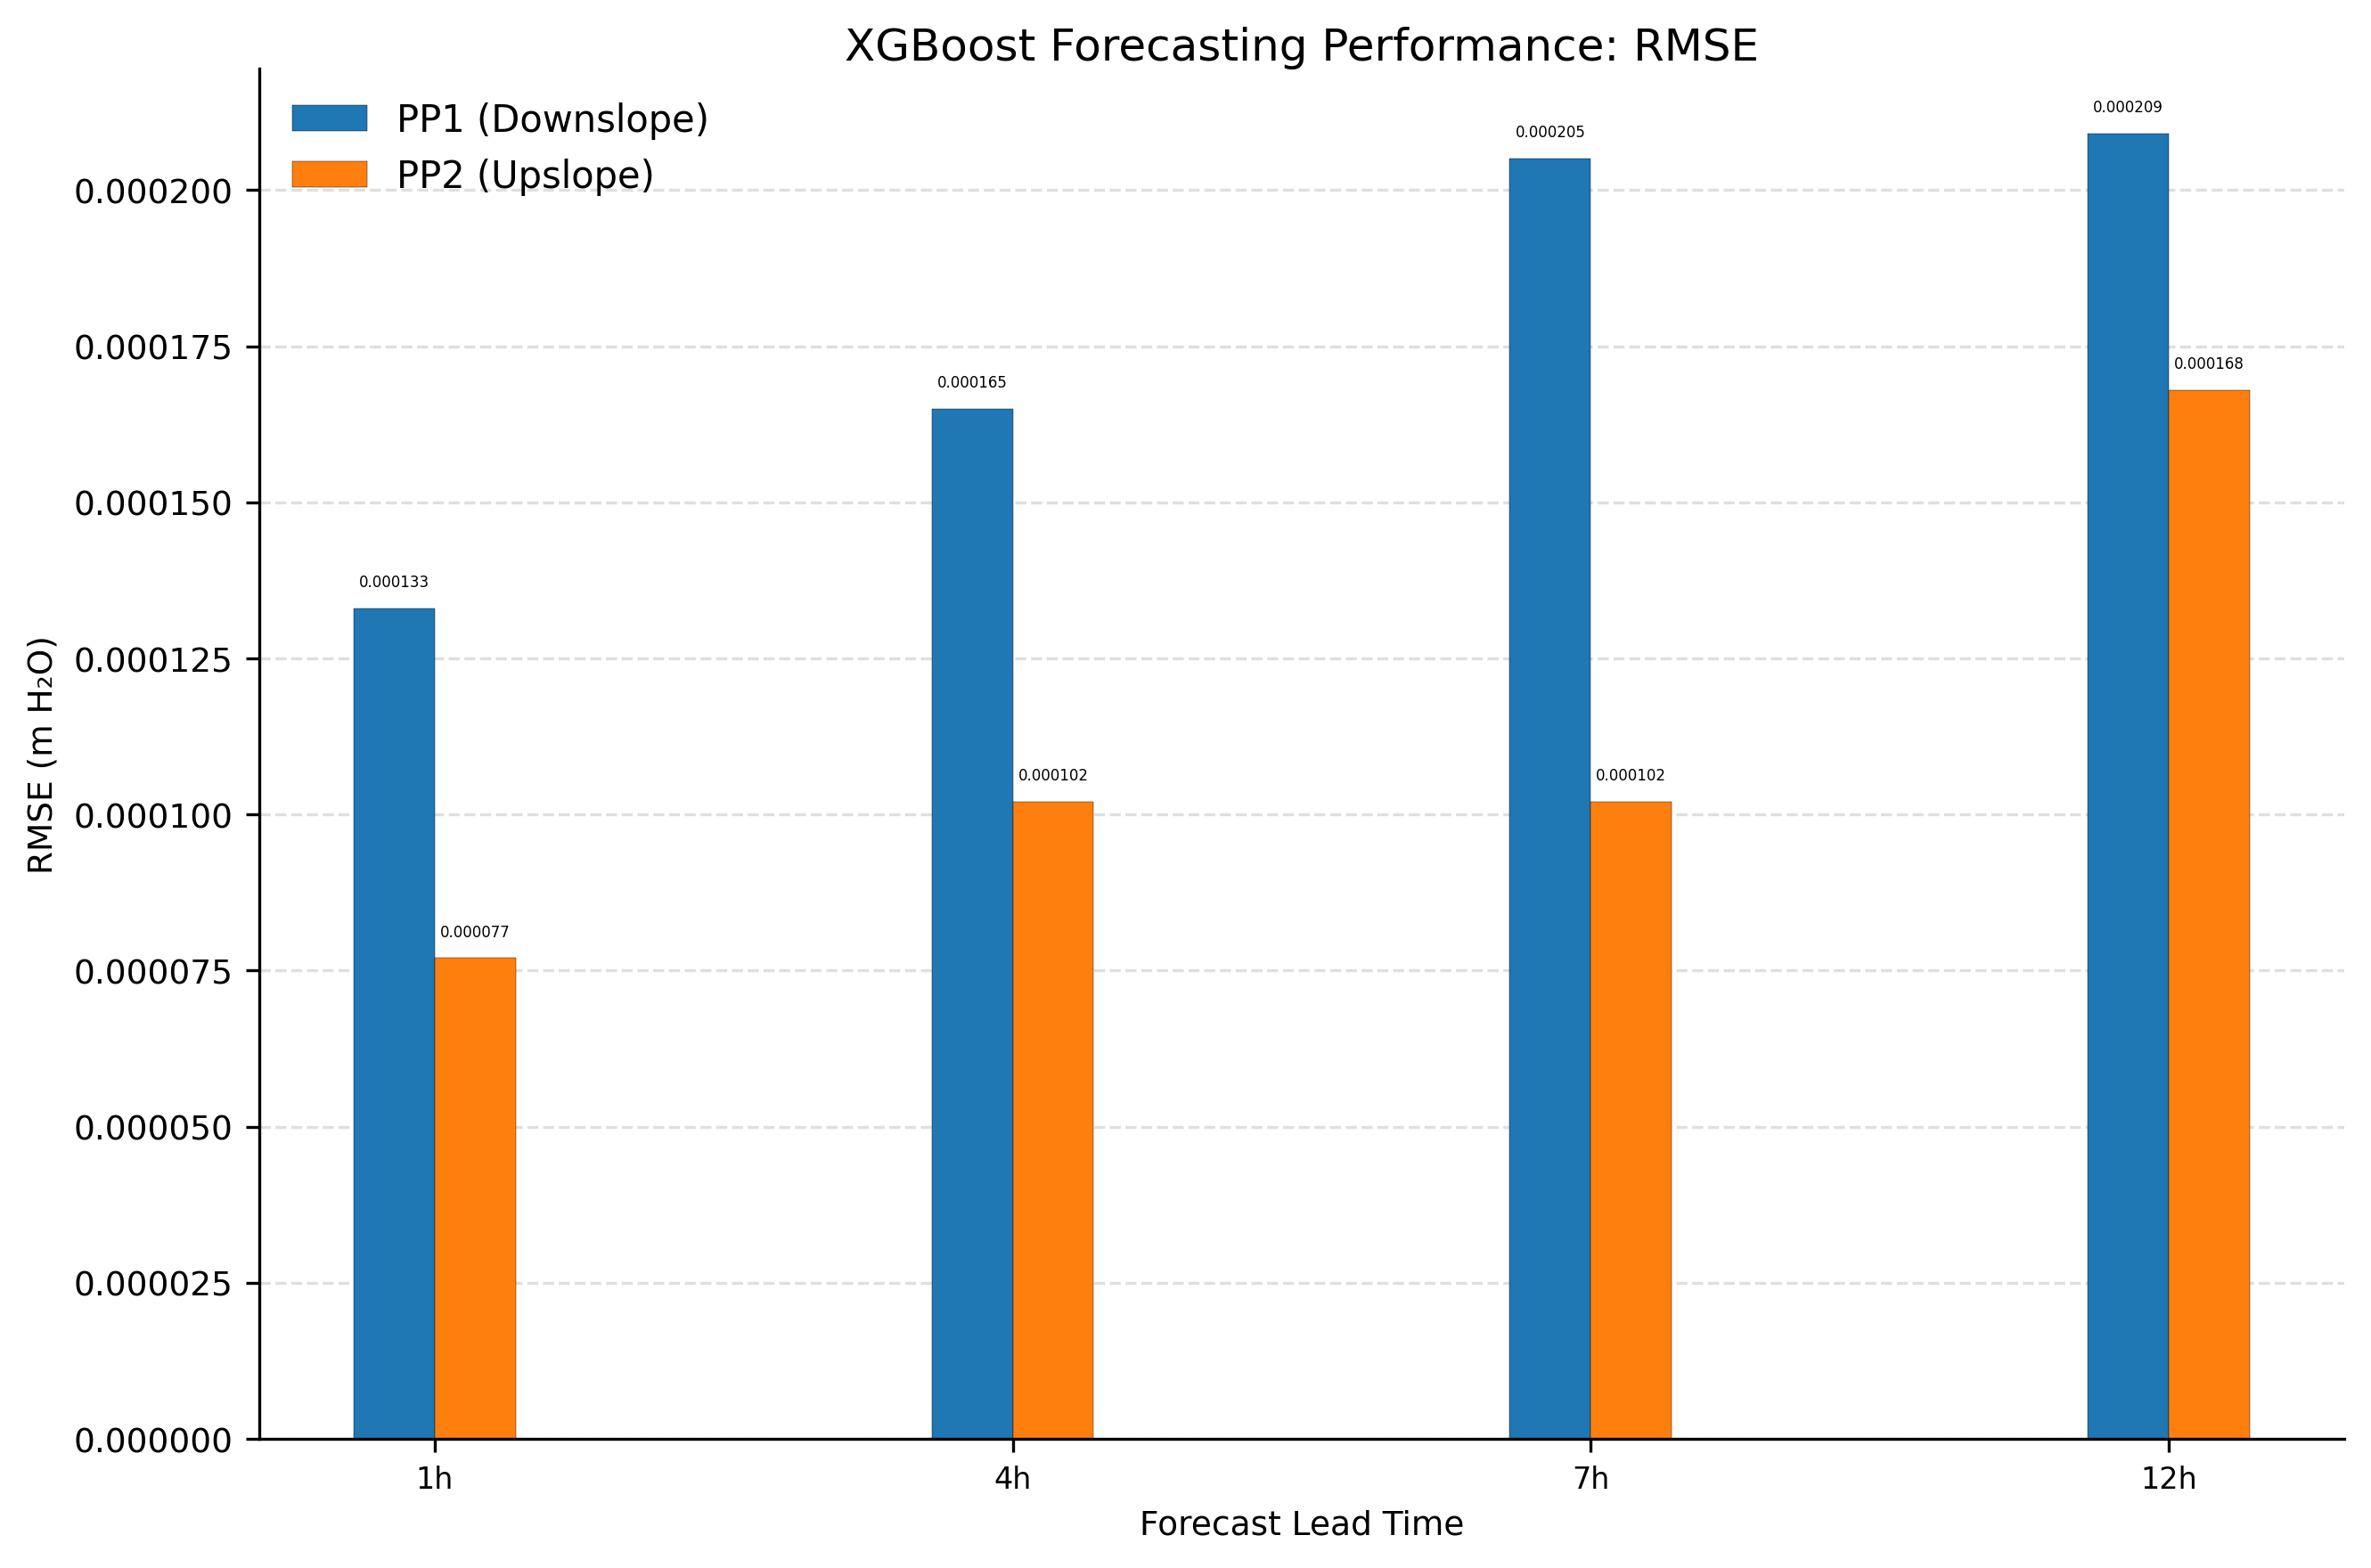

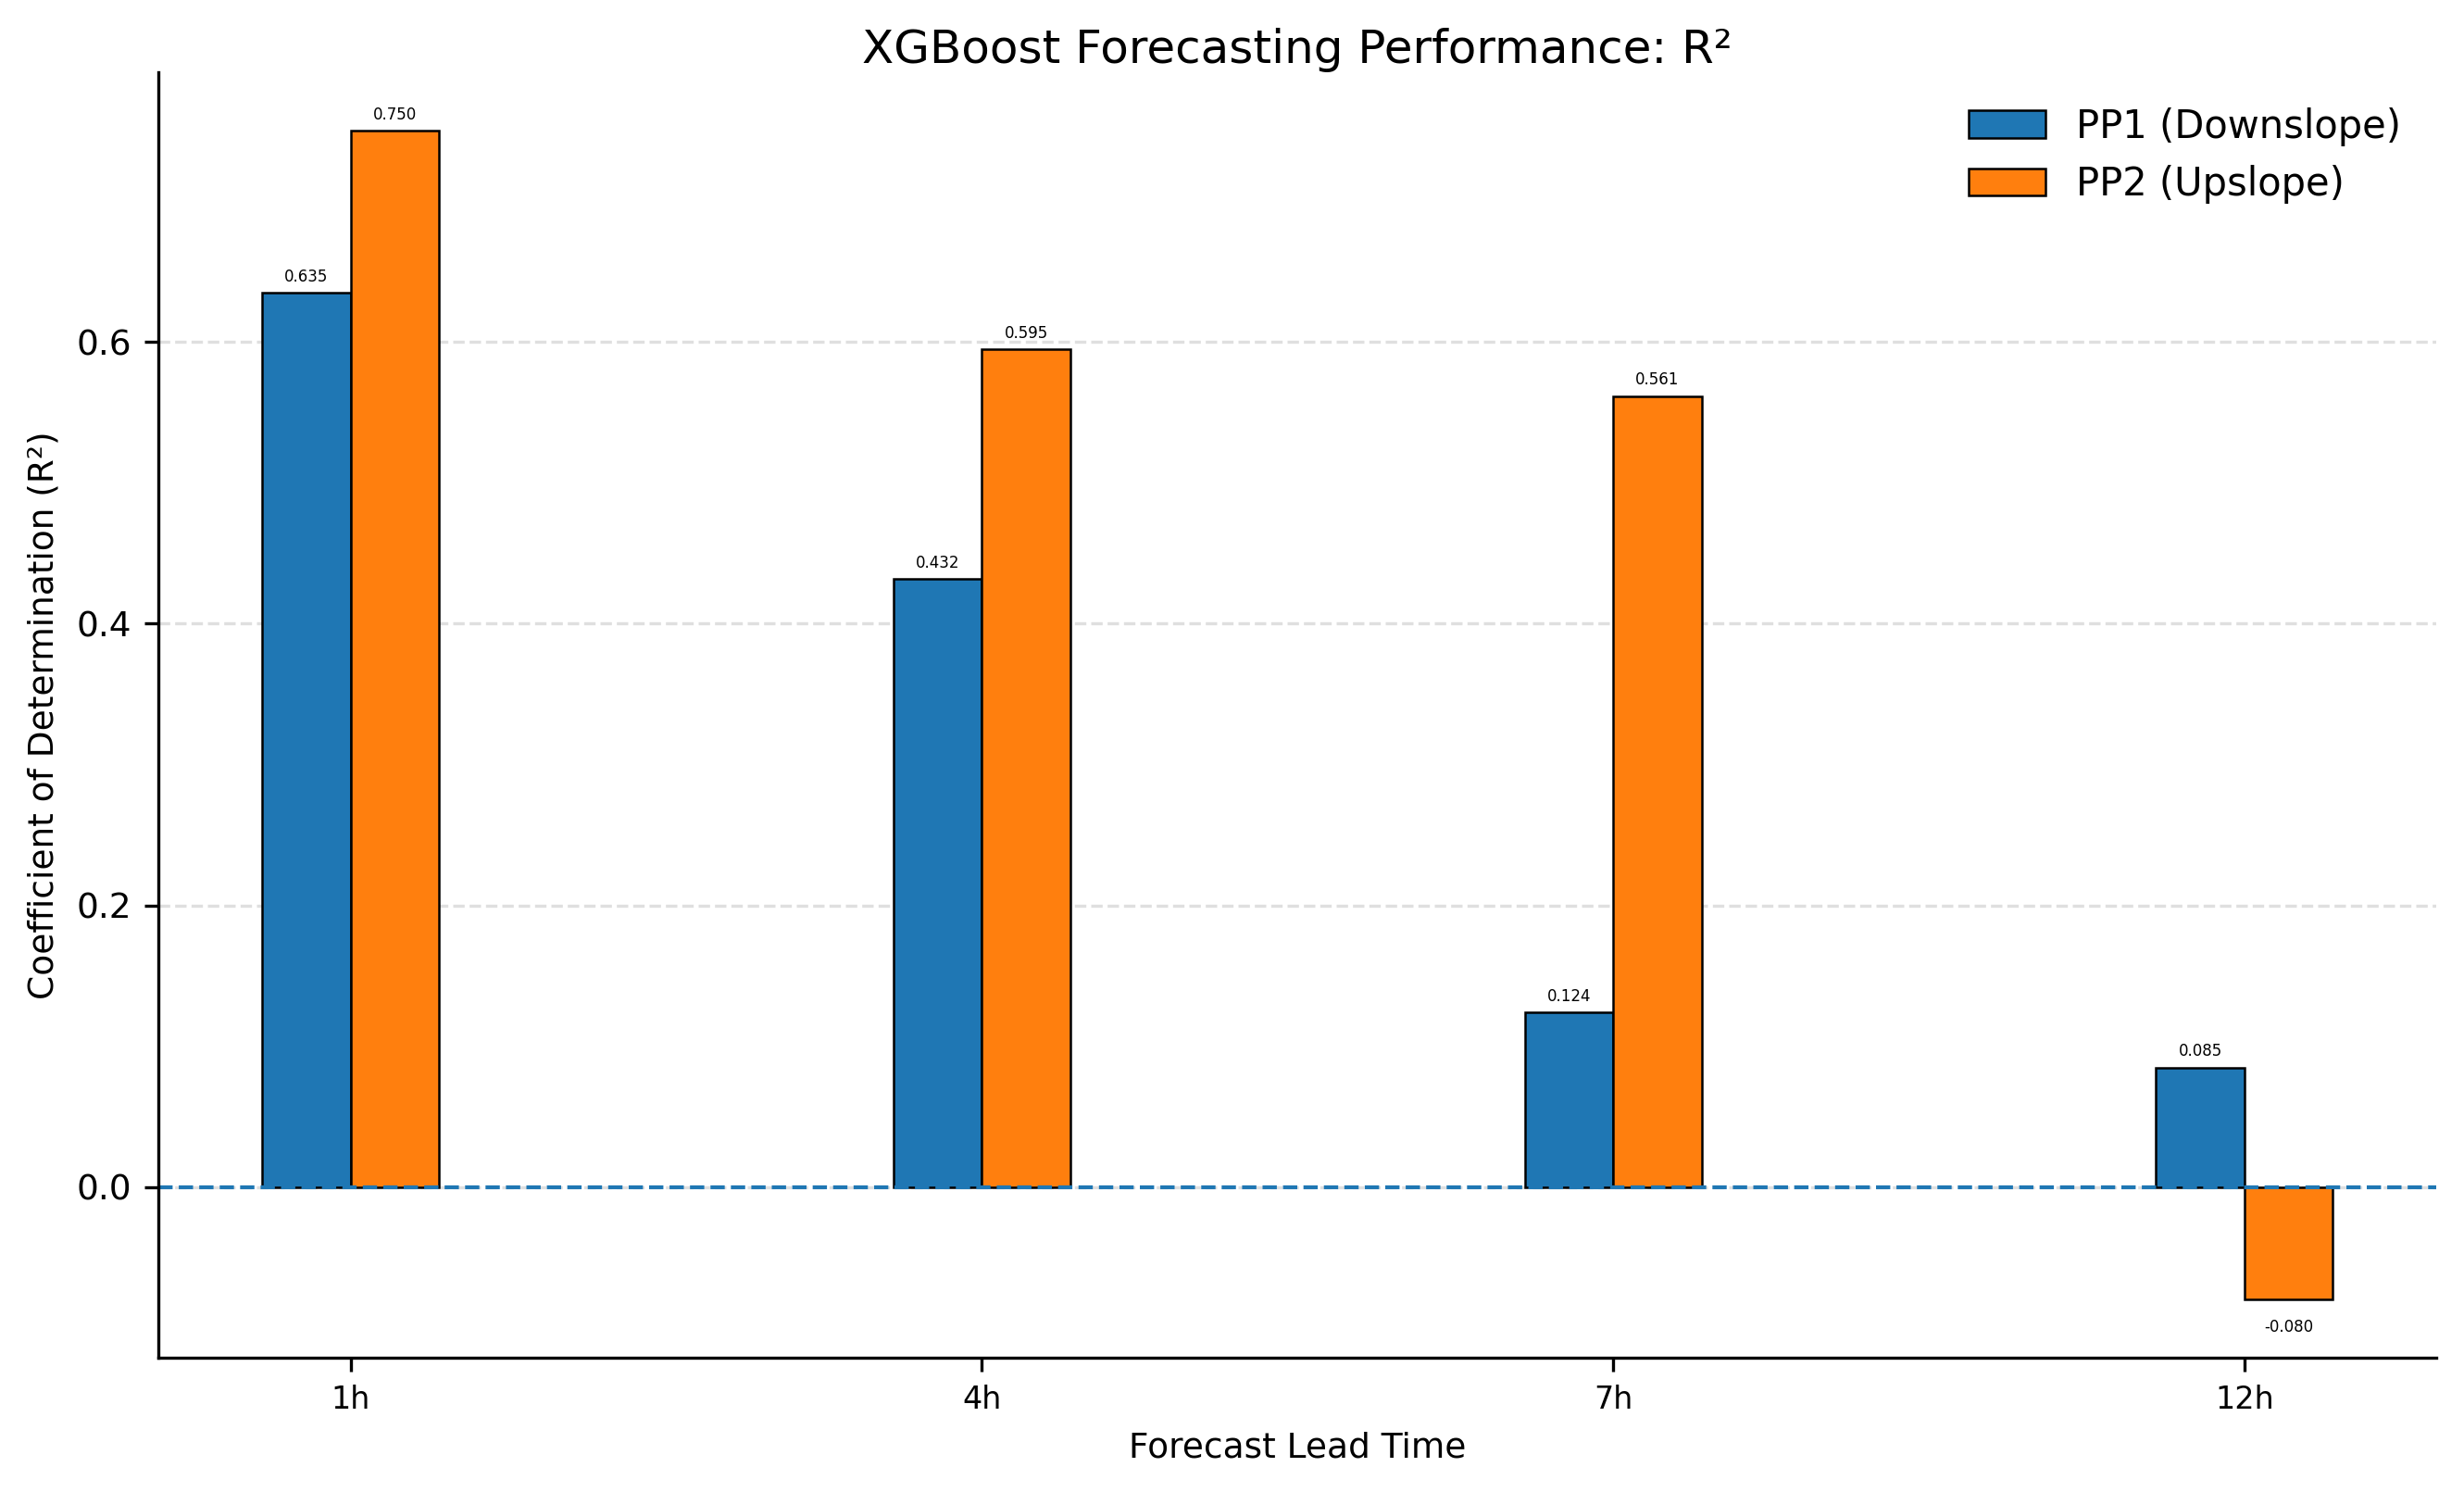

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# 1. RESULTS DATA
# ==========================================================

df = pd.DataFrame({
    "Lead Time": ["1h", "4h", "7h", "12h"],
    "RMSE_PP1": [0.000133, 0.000165, 0.000205, 0.000209],
    "RMSE_PP2": [0.000077, 0.000102, 0.000102, 0.000168],
    "R2_PP1": [0.634568, 0.431641, 0.123929, 0.084859],
    "R2_PP2": [0.749828, 0.594837, 0.561495, -0.079684]
})

# ==========================================================
# 2. PUBLICATION-QUALITY SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 9,
    "axes.titlesize": 12,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False
})

x = np.arange(len(df["Lead Time"]))
width = 0.14

# ==========================================================
# 3. CHART 1: RMSE COMPARISON
# ==========================================================

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width/2,
    df["RMSE_PP1"],
    width,
    label="PP1 (Downslope)",
    edgecolor="black",
    linewidth=0.1
)

bars2 = ax.bar(
    x + width/2,
    df["RMSE_PP2"],
    width,
    label="PP2 (Upslope)",
    edgecolor="black",
    linewidth=0.1
)

ax.set_title("XGBoost Forecasting Performance: RMSE", pad=0)
ax.set_xlabel("Forecast Lead Time")
ax.set_ylabel("RMSE (m H₂O)")
ax.set_xticks(x)
ax.set_xticklabels(df["Lead Time"])
ax.legend(frameon=False)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Numerical labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.6f}",
            xy=(bar.get_x() + bar.get_width()/2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=4,
            rotation=0
        )

plt.tight_layout()
plt.savefig("XGBoost_RMSE_Comparison.png", bbox_inches="tight")
plt.show()


# ==========================================================
# 4. CHART 2: R² COMPARISON
# ==========================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

bars1 = ax.bar(
    x - width/2,
    df["R2_PP1"],
    width,
    label="PP1 (Downslope)",
    edgecolor="black",
    linewidth=0.6
)

bars2 = ax.bar(
    x + width/2,
    df["R2_PP2"],
    width,
    label="PP2 (Upslope)",
    edgecolor="black",
    linewidth=0.6
)

ax.axhline(
    y=0,
    linewidth=1,
    linestyle="--"
)

ax.set_title("XGBoost Forecasting Performance: R²", pad=0)
ax.set_xlabel("Forecast Lead Time")
ax.set_ylabel("Coefficient of Determination (R²)")
ax.set_xticks(x)
ax.set_xticklabels(df["Lead Time"])
ax.legend(frameon=False)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Numerical labels, positioned correctly for positive and negative bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        offset = 2 if height >= 0 else -5
        ax.annotate(
            f"{height:.3f}",
            xy=(bar.get_x() + bar.get_width()/2, height),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=4
        )

plt.tight_layout()
plt.savefig("XGBoost_R2_Comparison.png", bbox_inches="tight")
plt.show()


###Plot Time Series for Each Lead Time

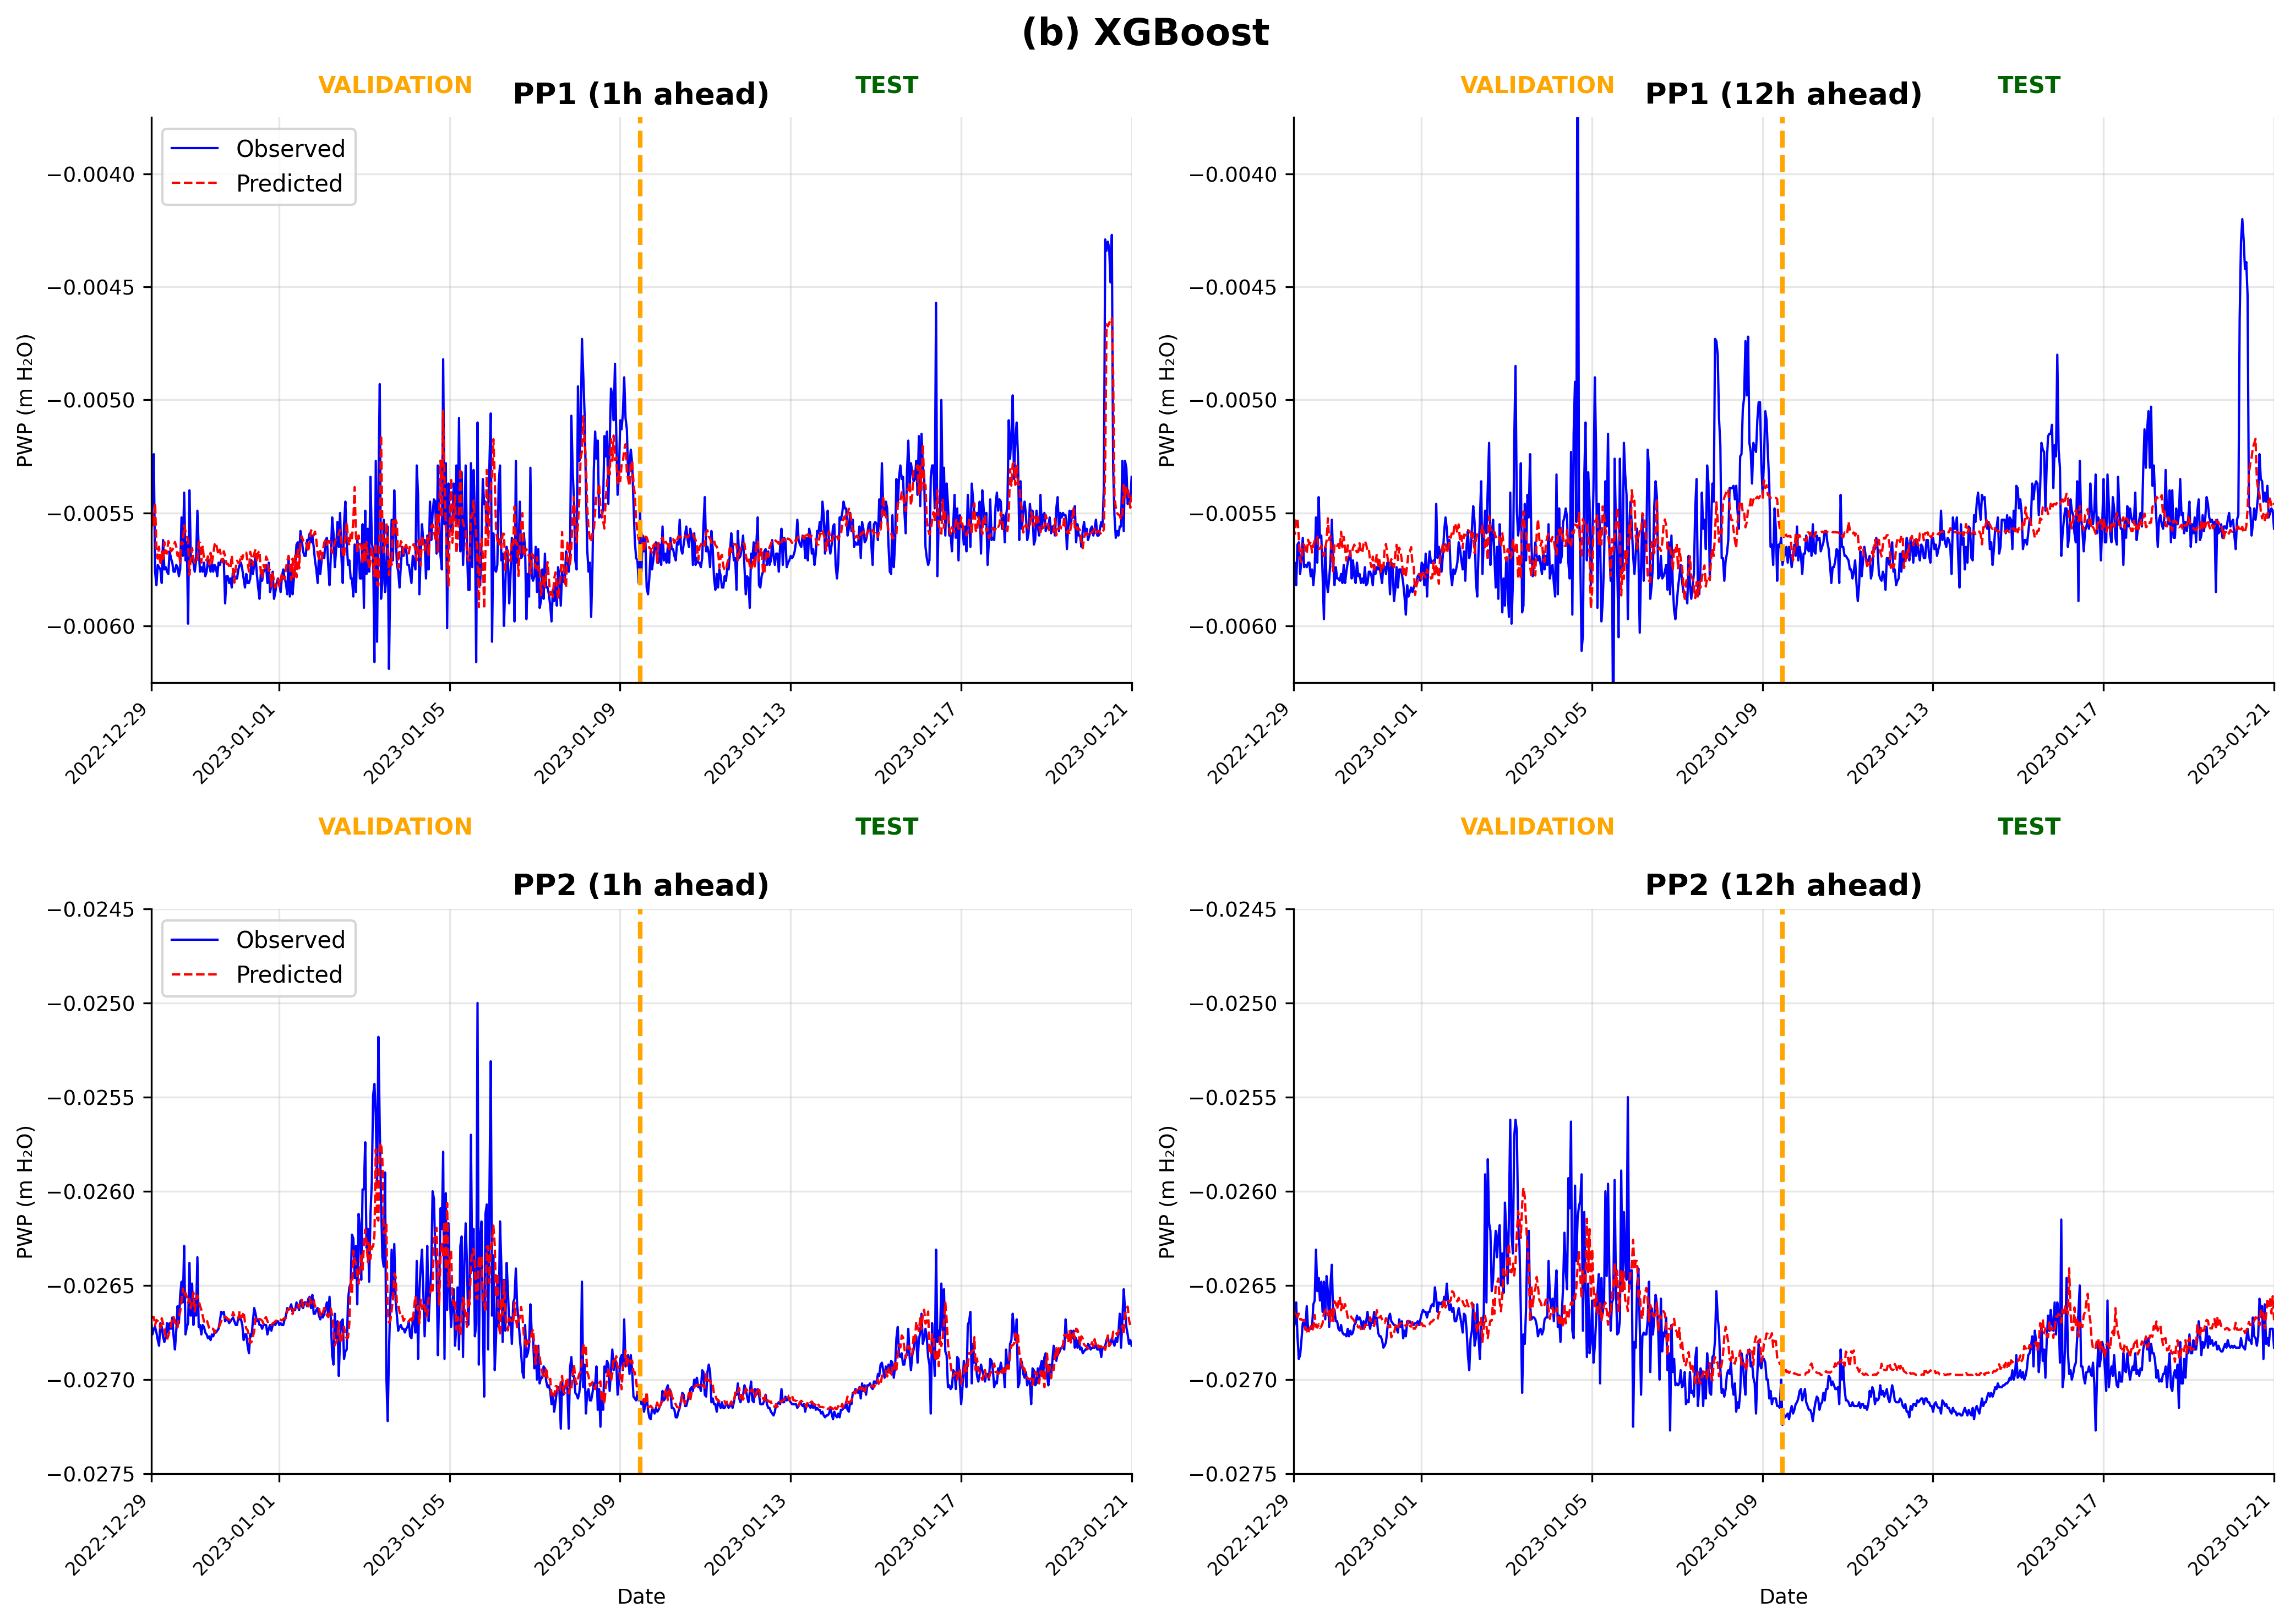

Representative XGBoost figure saved successfully.


In [16]:
# ============================================================
# XGBOOST REPRESENTATIVE FORECASTS FOR MANUSCRIPT
# PP1 & PP2 AT 1h AND 12h LEAD TIMES
# USING SAME DATE AXIS AS LSTM & SVR
# ============================================================

from datetime import datetime, timedelta
from matplotlib.dates import DateFormatter
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# VAL/TEST TIMESTAMPS
# ============================================================

n_val = len(X_val)
n_test = len(X_test)

val_test_length = n_val + n_test

val_start_date = datetime(2022, 12, 29, 0, 0)
end_date = datetime(2023, 1, 21, 0, 0)

total_valtest_minutes = (
    end_date - val_start_date
).total_seconds() / 60

val_test_indices = np.linspace(
    0,
    total_valtest_minutes,
    val_test_length,
    endpoint=True
)

val_test_times = np.array([
    val_start_date + timedelta(minutes=int(minutes))
    for minutes in val_test_indices
])

val_end_time = val_test_times[n_val - 1]

# ============================================================
# DATE TICKS
# ============================================================

exact_ticks_valtest = [
    datetime(2022, 12, 29),
    datetime(2023, 1, 1),
    datetime(2023, 1, 5),
    datetime(2023, 1, 9),
    datetime(2023, 1, 13),
    datetime(2023, 1, 17),
    datetime(2023, 1, 21)
]

date_formatter = DateFormatter('%Y-%m-%d')

# ============================================================
# SELECTED HORIZONS
# ============================================================

selected_horizons = [0, 11]
selected_labels = ["1h", "12h"]

# ============================================================
# GENERATE PREDICTIONS
# ============================================================

results = {}

for h_idx, h_label in zip(selected_horizons, selected_labels):

    model_pp1_h = xgb_models[h_label]["model_pp1"]
    model_pp2_h = xgb_models[h_label]["model_pp2"]

    pred1_val = model_pp1_h.predict(X_val)
    pred1_test = model_pp1_h.predict(X_test)

    pred2_val = model_pp2_h.predict(X_val)
    pred2_test = model_pp2_h.predict(X_test)

    y1_val_true = Y5[train_end:val_end, h_idx, 0]
    y1_test_true = Y5[val_end:, h_idx, 0]

    y2_val_true = Y5[train_end:val_end, h_idx, 1]
    y2_test_true = Y5[val_end:, h_idx, 1]

    results[h_label] = {

        "pp1_pred_all":
            np.concatenate([pred1_val, pred1_test]),

        "pp1_true_all":
            np.concatenate([y1_val_true, y1_test_true]),

        "pp2_pred_all":
            np.concatenate([pred2_val, pred2_test]),

        "pp2_true_all":
            np.concatenate([y2_val_true, y2_test_true])
    }

# ============================================================
# FIXED Y LIMITS
# ============================================================

PP1_YLIM = (-0.00625, -0.00375)
PP2_YLIM = (-0.0275, -0.0245)

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "(b) XGBoost",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# PLOT
# ============================================================

for col, h_label in enumerate(selected_labels):

    # ========================================================
    # PP1
    # ========================================================

    ax = axes[0, col]

    pp1_true = results[h_label]["pp1_true_all"]
    pp1_pred = results[h_label]["pp1_pred_all"]

    ax.plot(
        val_test_times,
        pp1_true,
        color='blue',
        linewidth=1,
        label='Observed'
    )

    ax.plot(
        val_test_times,
        pp1_pred,
        color='red',
        linestyle='--',
        linewidth=1,
        label='Predicted'
    )

    ax.axvline(
        x=val_end_time,
        color='orange',
        linestyle='--',
        linewidth=2
    )

    ax.text(
        val_test_times[n_val//2],
        PP1_YLIM[1] * 0.95,
        'VALIDATION',
        ha='center',
        va='top',
        fontsize=10,
        fontweight='bold',
        color='orange'
    )

    ax.text(
        val_test_times[-n_test//2],
        PP1_YLIM[1] * 0.95,
        'TEST',
        ha='center',
        va='top',
        fontsize=10,
        fontweight='bold',
        color='darkgreen'
    )

    ax.set_title(
        f'PP1 ({h_label} ahead)',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_ylabel('PWP (m H₂O)')

    ax.set_ylim(PP1_YLIM)

    ax.set_xlim(
        val_test_times[0],
        val_test_times[-1]
    )

    ax.set_xticks(exact_ticks_valtest)

    ax.xaxis.set_major_formatter(date_formatter)

    plt.setp(
        ax.xaxis.get_majorticklabels(),
        rotation=45,
        ha='right'
    )

    ax.grid(True, alpha=0.3)

    if col == 0:
        ax.legend(loc='upper left')

    # ========================================================
    # PP2
    # ========================================================

    ax = axes[1, col]

    pp2_true = results[h_label]["pp2_true_all"]
    pp2_pred = results[h_label]["pp2_pred_all"]

    ax.plot(
        val_test_times,
        pp2_true,
        color='blue',
        linewidth=1,
        label='Observed'
    )

    ax.plot(
        val_test_times,
        pp2_pred,
        color='red',
        linestyle='--',
        linewidth=1,
        label='Predicted'
    )

    ax.axvline(
        x=val_end_time,
        color='orange',
        linestyle='--',
        linewidth=2
    )

    ax.text(
        val_test_times[n_val//2],
        PP2_YLIM[1] * 0.98,
        'VALIDATION',
        ha='center',
        va='top',
        fontsize=10,
        fontweight='bold',
        color='orange'
    )

    ax.text(
        val_test_times[-n_test//2],
        PP2_YLIM[1] * 0.98,
        'TEST',
        ha='center',
        va='top',
        fontsize=10,
        fontweight='bold',
        color='darkgreen'
    )

    ax.set_title(
        f'PP2 ({h_label} ahead)',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlabel('Date')

    ax.set_ylabel('PWP (m H₂O)')

    ax.set_ylim(PP2_YLIM)

    ax.set_xlim(
        val_test_times[0],
        val_test_times[-1]
    )

    ax.set_xticks(exact_ticks_valtest)

    ax.xaxis.set_major_formatter(date_formatter)

    plt.setp(
        ax.xaxis.get_majorticklabels(),
        rotation=45,
        ha='right'
    )

    ax.grid(True, alpha=0.3)

    if col == 0:
        ax.legend(loc='upper left')

# ============================================================
# SAVE
# ============================================================

plt.tight_layout()

plt.savefig(
    "XGBoost_Representative_1h_12h_DateAxis.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "XGBoost_Representative_1h_12h_DateAxis.pdf",
    dpi=1200,
    bbox_inches="tight"

)

plt.show()

print("Representative XGBoost figure saved successfully.")

## 6. Explainability: gain-based feature importance and optional SHAP

**Research Question**

Which historical hydrological observations contribute most to XGBoost's prediction of future pore-water pressure, and how do their contributions differ between the downslope (PP1) and upslope (PP2) locations?


TOP 20 FEATURES - PP1 (DOWNSLOPE)


,Gain
PP1_Downslope_lag45,0.000090
PP1_Downslope_lag24,0.000029
PP1_Downslope_lag48,0.000026
PP1_Downslope_lag42,0.000023
PP2_Upslope_lag1,0.000022
PP2_Upslope_lag27,0.000022
SM2_Downslope_25cm_lag2,0.000022
SM5_Upslope_25cm_lag1,0.000021
PP2_Upslope_lag2,0.000020
PP1_Downslope_lag22,0.000018


TOP 20 FEATURES - PP2 (UPSLOPE)


,Gain
PP2_Upslope_lag48,0.000064
PP2_Upslope_lag47,0.000064
PP2_Upslope_lag39,0.000040
PP2_Upslope_lag43,0.000036
PP2_Upslope_lag46,0.000018
PP2_Upslope_lag40,0.000017
PP2_Upslope_lag33,0.000012
PP2_Upslope_lag35,0.000010
PP2_Upslope_lag31,0.000006
PP2_Upslope_lag29,0.000006


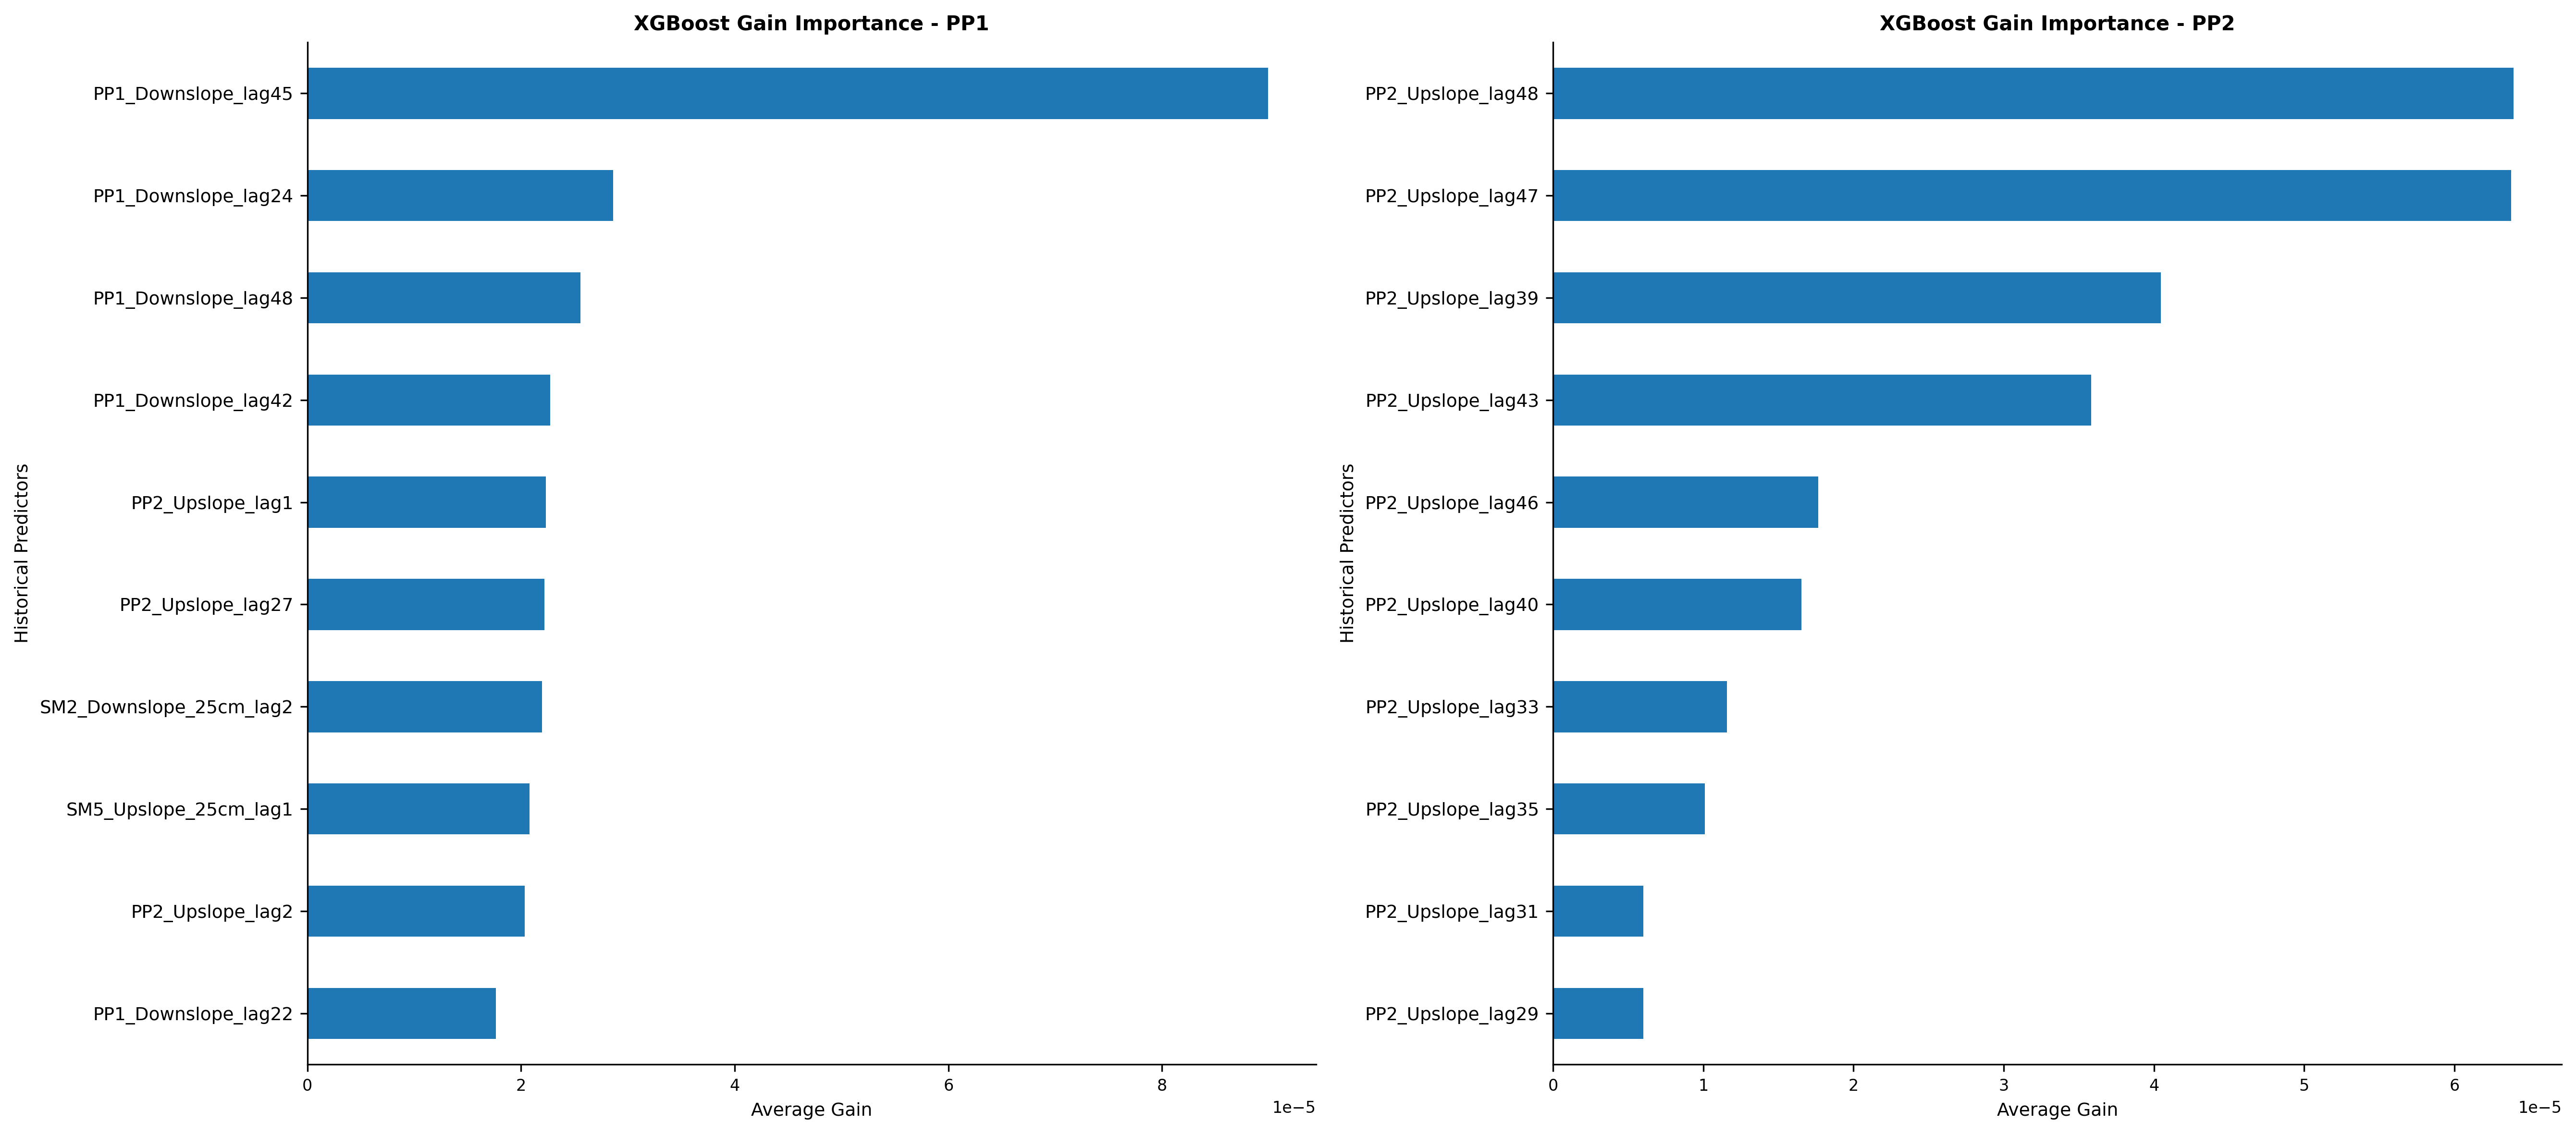

In [28]:

# ============================================================
# XGBOOST EXPLAINABILITY: GAIN-BASED FEATURE IMPORTANCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Original seven input variables
feature_names = [
    "Rainfall",
    "SM1_Downslope_55cm",
    "SM2_Downslope_25cm",
    "SM4_Upslope_55cm",
    "SM5_Upslope_25cm",
    "PP1_Downslope",
    "PP2_Upslope"
]

L = 48
F = len(feature_names)

# Verify input dimensions
assert X_train.shape[1] == L * F, (
    f"Expected {L*F} features, received {X_train.shape[1]}"
)

# Create names for all 336 lagged predictors
lagged_feature_names = [
    f"{feature}_lag{lag+1}"
    for lag in range(L)
    for feature in feature_names
]

# ------------------------------------------------------------
# Select XGBoost model
# ------------------------------------------------------------

horizon = "1h"

model_pp1 = xgb_models[horizon]["model_pp1"]
model_pp2 = xgb_models[horizon]["model_pp2"]

# ------------------------------------------------------------
# Extract gain importance
# ------------------------------------------------------------

def extract_gain(model, names):

    booster = model.get_booster()

    gain_dict = booster.get_score(
        importance_type="gain"
    )

    importance = pd.Series(
        {
            names[i]: gain_dict.get(f"f{i}", 0)
            for i in range(len(names))
        }
    )

    return importance.sort_values(ascending=False)


gain_pp1 = extract_gain(
    model_pp1,
    lagged_feature_names
)

gain_pp2 = extract_gain(
    model_pp2,
    lagged_feature_names
)

# ------------------------------------------------------------
# Display top 20 features
# ------------------------------------------------------------

print("TOP 20 FEATURES - PP1 (DOWNSLOPE)")
display(gain_pp1.head(10).to_frame("Gain"))

print("TOP 20 FEATURES - PP2 (UPSLOPE)")
display(gain_pp2.head(10).to_frame("Gain"))

# ------------------------------------------------------------
# Plot feature importance
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

gain_pp1.head(10).sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title(
    "XGBoost Gain Importance - PP1",
    fontsize=10,
    fontweight="bold"
)

axes[0].set_xlabel("Average Gain")
axes[0].set_ylabel("Historical Predictors")

gain_pp2.head(10).sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title(
    "XGBoost Gain Importance - PP2",
    fontsize=10,
    fontweight="bold"
)

axes[1].set_xlabel("Average Gain")
axes[1].set_ylabel("Historical Predictors")

plt.tight_layout()

plt.savefig(
    "XGBoost_Gain_Importance_PP1_PP2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


###Explainability
XGBoost gain-importance results reveal an important finding:
the two slope positions exhibit different patterns of temporal dependence in pore-water pressure prediction. The downslope and upslope models rely on different combinations of historical sensor measurements.
####PP1 — Downslope pore-water pressure
The PP1 model is dominated by its own historical pore-water pressure measurements.
Historical PP1 measurements are the most influential predictors.

* PP2 also contributes, suggesting that upslope pressure contains useful information for predicting downslope pressure.

* SM2 (downslope soil moisture at 25 cm) appears repeatedly among the influential predictors.

* Rainfall appears in the top 20, but its gain is lower than that of the pressure measurements.

####PP2 — Upslope pore-water pressure
* PP2 historical pressure dominates the model's top-ranked predictors.
* Several influential features are concentrated around lags 39–48.
* SM1 (downslope soil moisture at 55 cm) appears among the top 12 predictors.
* Other predictors, including rainfall and the remaining soil-moisture
* measurements, have relatively little representation in the top 20.

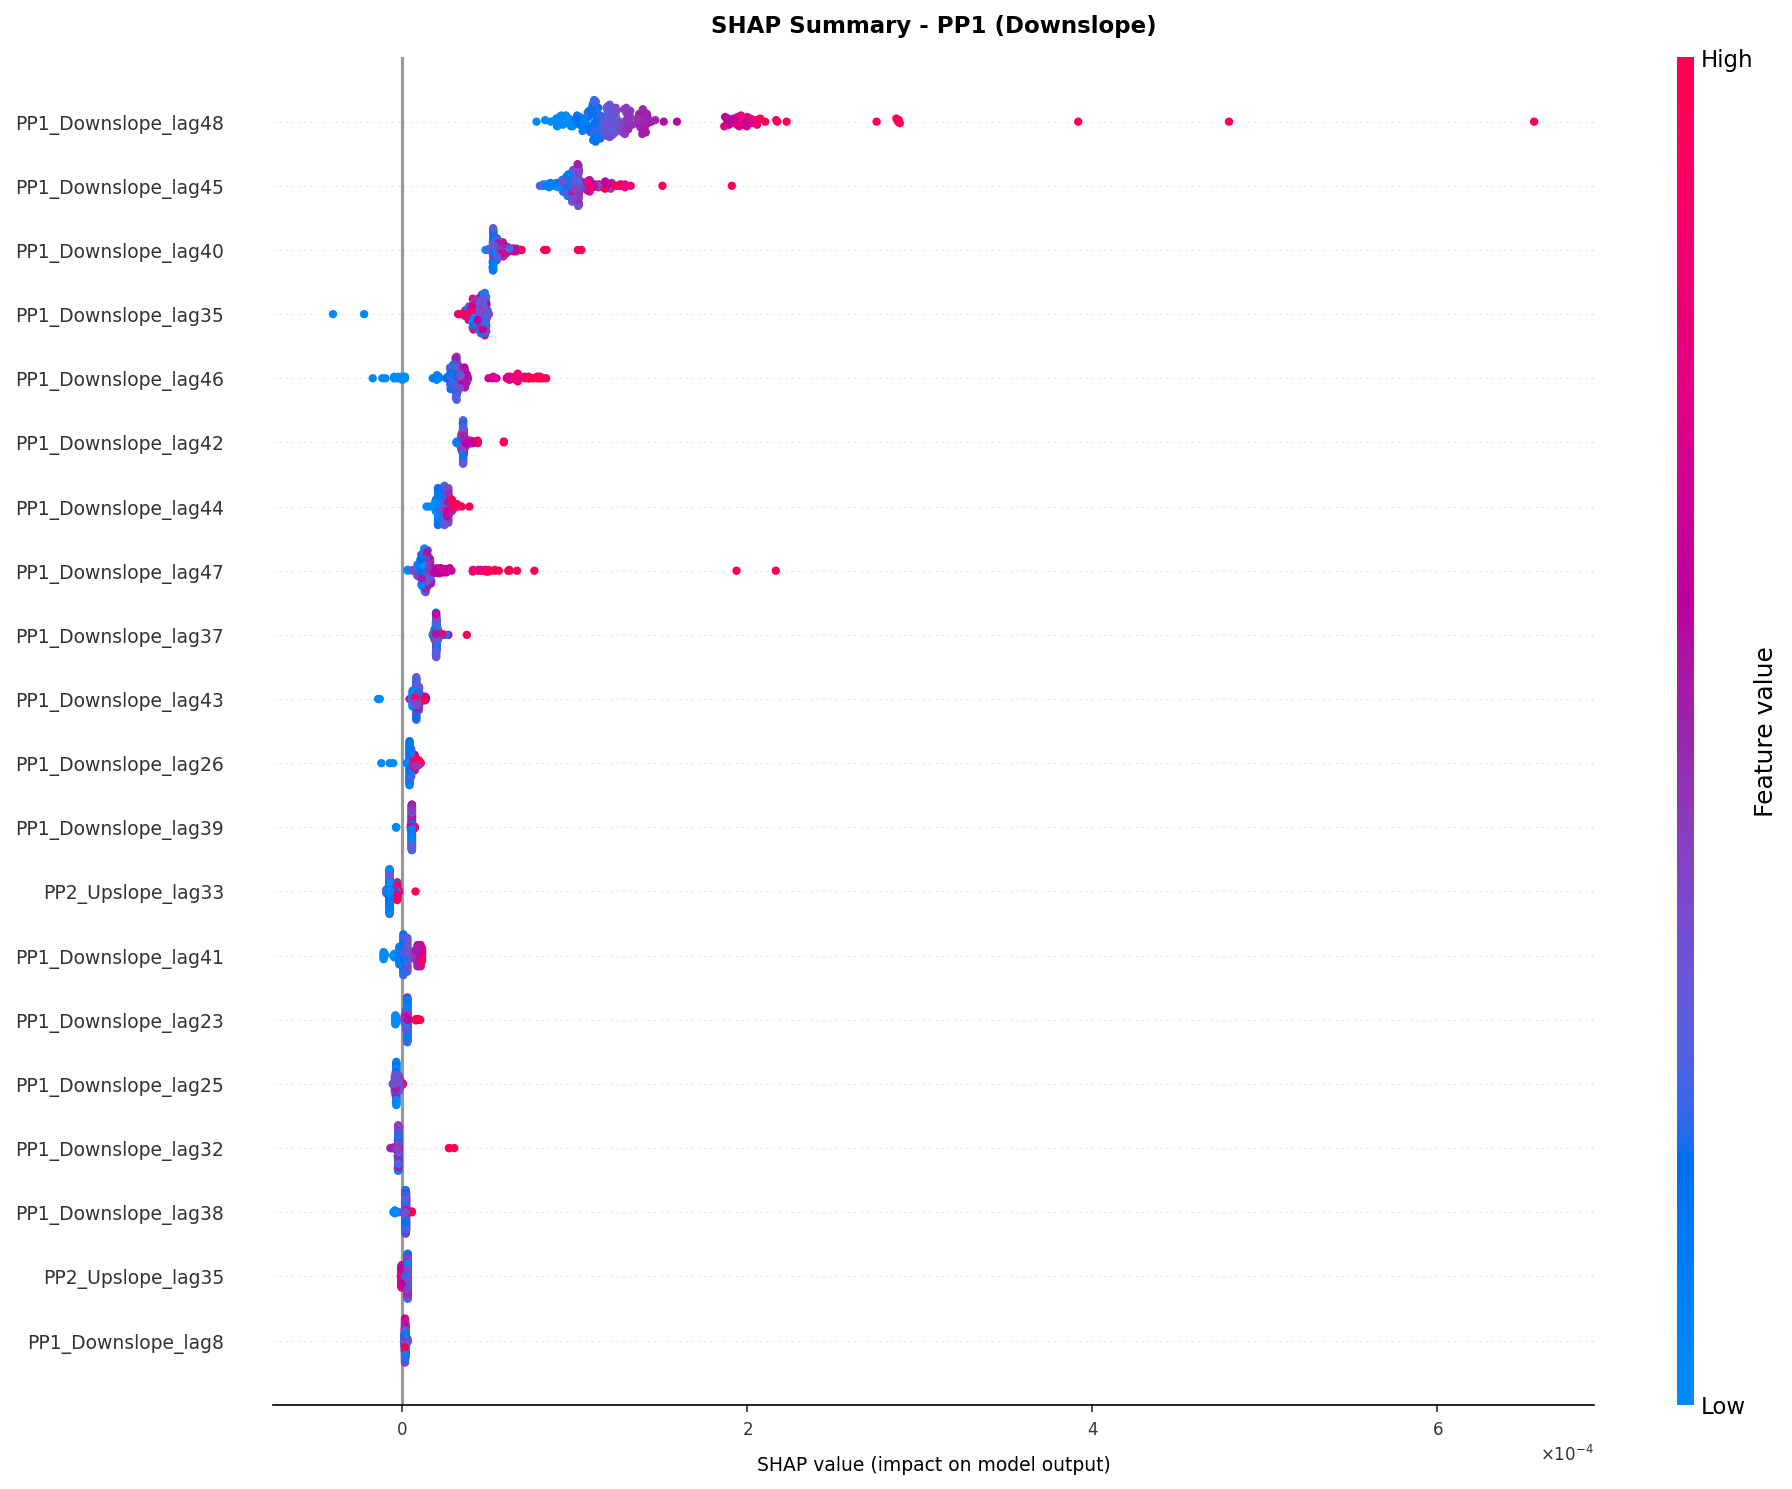

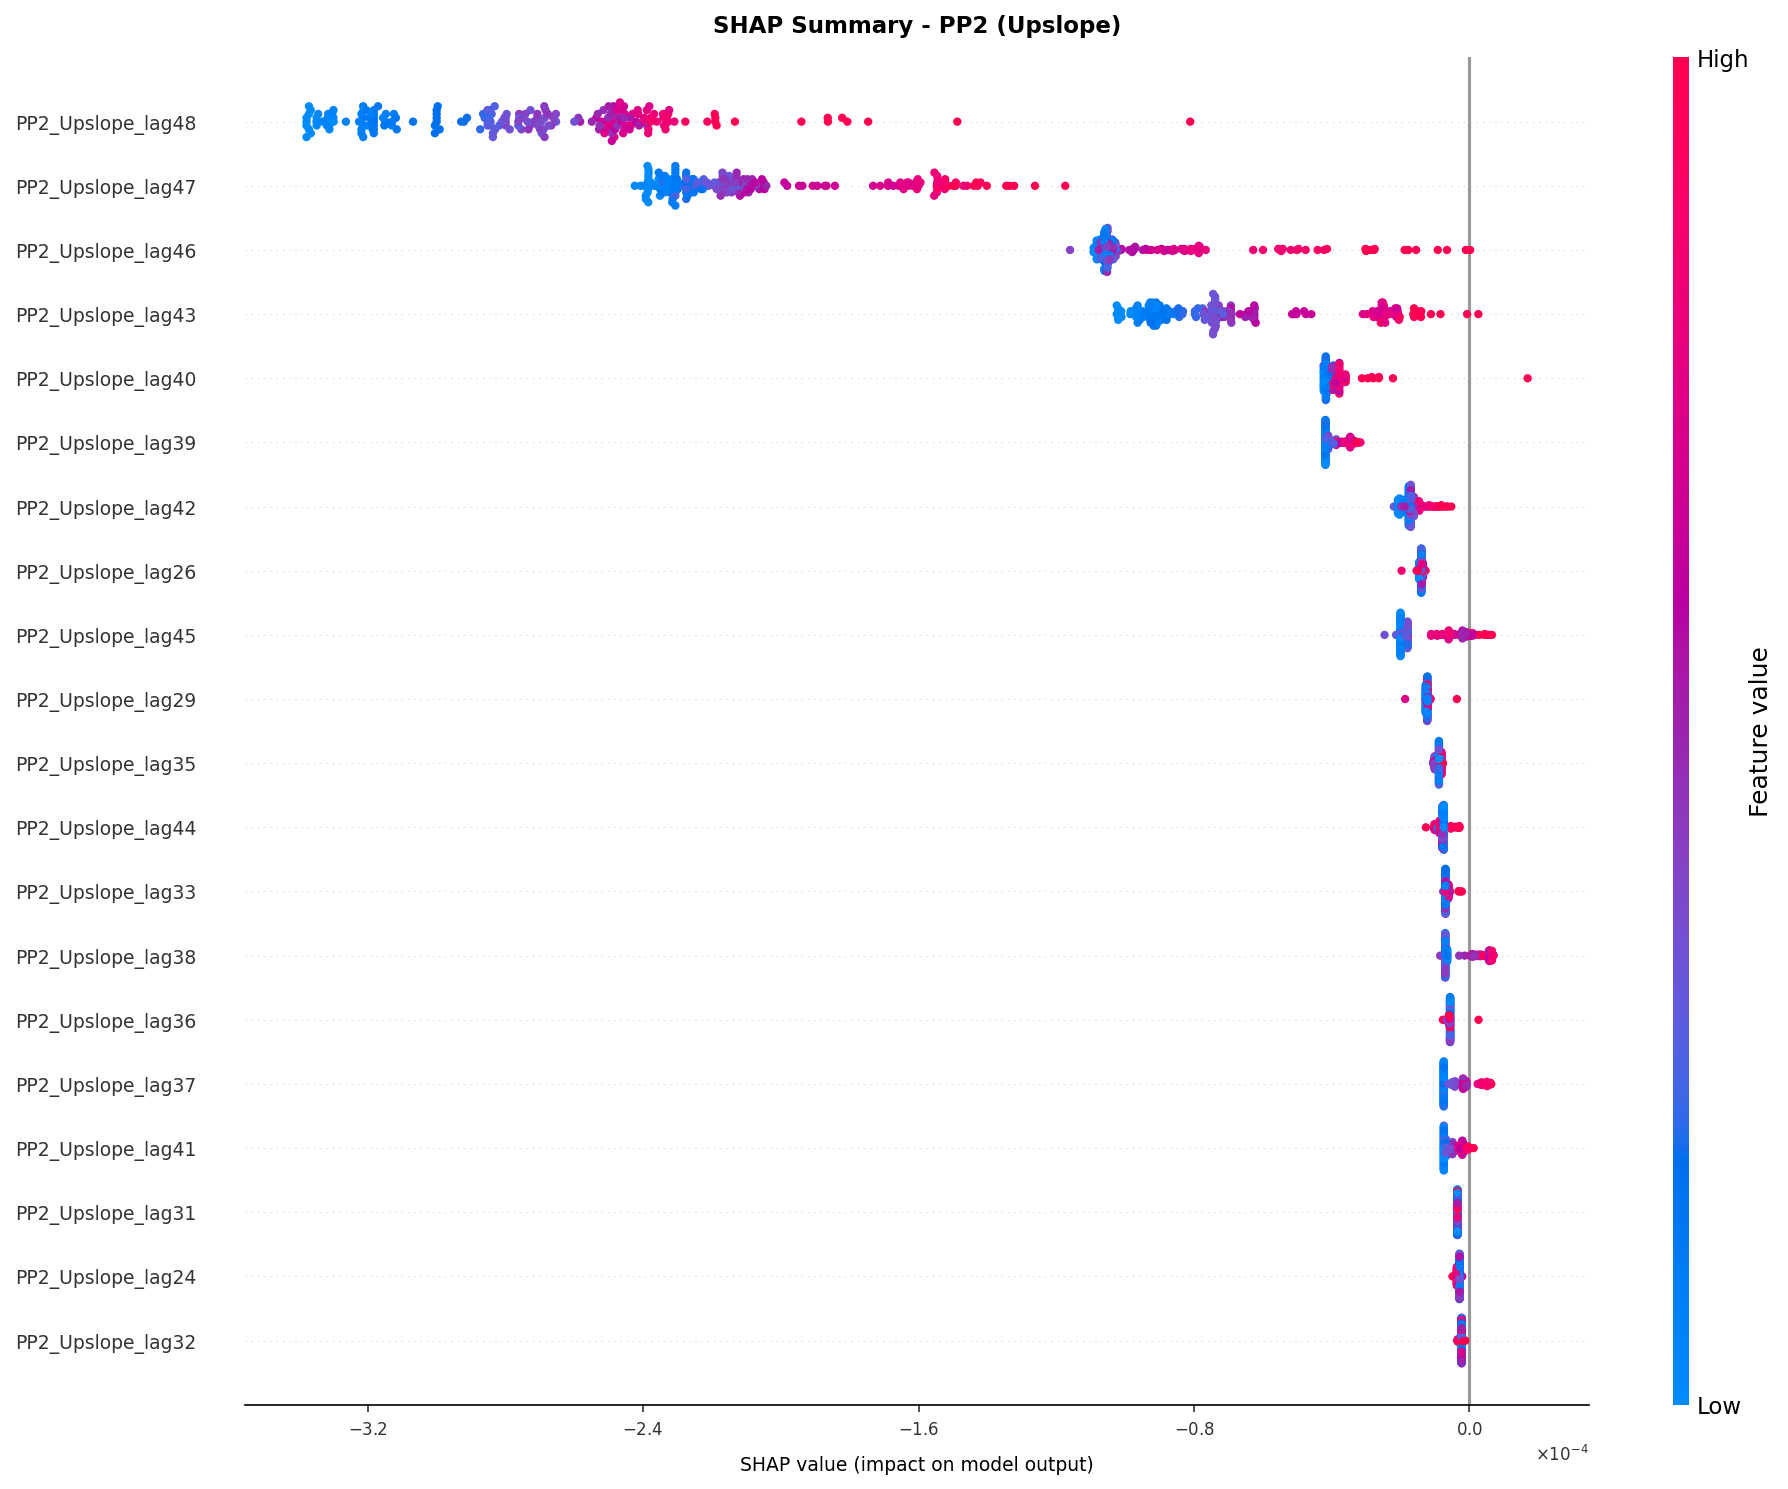

In [30]:

# ============================================================
# 4–5. GLOBAL SHAP SUMMARY PLOTS: PP1 AND PP2
# PUBLICATION-QUALITY FORMATTING
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ------------------------------------------------------------
# Publication formatting
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600
})

# ------------------------------------------------------------
# Function to generate formatted SHAP summary plots
# ------------------------------------------------------------

def plot_shap_summary(
    shap_values,
    X_data,
    feature_names,
    title,
    output_file
):

    plt.figure(figsize=(13, 10))

    shap.summary_plot(
        shap_values,
        X_data,
        feature_names=feature_names,
        max_display=20,
        show=False,
        plot_size=None
    )

    # Get the main SHAP plotting axis
    ax = plt.gca()

    # Reduce horizontal-axis tick font
    ax.tick_params(
        axis="x",
        labelsize=8,
        pad=4
    )

    # Reduce the number of horizontal-axis ticks
    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    # Display SHAP values in scientific notation
    ax.ticklabel_format(
        axis="x",
        style="sci",
        scilimits=(0, 0),
        useMathText=True
    )

    # Horizontal-axis label
    ax.set_xlabel(
        "SHAP value (impact on model output)",
        fontsize=9,
        labelpad=8
    )

    # Vertical-axis labels
    ax.tick_params(
        axis="y",
        labelsize=9
    )

    # Title
    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold",
        pad=12
    )

    # Improve layout
    plt.tight_layout()

    # Save high-resolution figure
    plt.savefig(
        output_file,
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    plt.close()


# ============================================================
# 6. SHAP SUMMARY — PP1 (DOWNSLOPE)
# ============================================================

plot_shap_summary(
    shap_values=shap_pp1.values,
    X_data=X_explain,
    feature_names=lagged_feature_names,
    title="SHAP Summary - PP1 (Downslope)",
    output_file="SHAP_PP1_Summary.png"
)


# ============================================================
# 7. SHAP SUMMARY — PP2 (UPSLOPE)
# ============================================================

plot_shap_summary(
    shap_values=shap_pp2.values,
    X_data=X_explain,
    feature_names=lagged_feature_names,
    title="SHAP Summary - PP2 (Upslope)",
    output_file="SHAP_PP2_Summary.png"
)


##EXPLAINABILITY
The most important finding is that both models rely heavily on their own historical pore-water pressure measurements, but the patterns of influence differ between the downslope and upslope locations.
1. How to read the SHAP plots
There are three things to understand:
- Vertical axis (features): The historical measurements, ranked from most important at the top to less important below.
- Horizontal axis (SHAP value): How much a feature contributes to the model's prediction relative to its baseline prediction.
- Colour: The actual feature value for each observation.
  - Red/pink = high feature value.
  - Blue = low feature value.
Each dot represents one observation in your dataset.

A positive SHAP value pushes the model prediction above its baseline; a negative SHAP value pushes it below its baseline
####PP1 — Downslope model
The downslope prediction appears to be strongly informed by its own historical pore-pressure state, with some additional information from the upslope pressure sensor.
1. PP1_Downslope_lag48
2. PP1_Downslope_lag45
3. PP1_Downslope_lag40
4. PP1_Downslope_lag35
5. PP1_Downslope_lag46
####PP2 — Downslope model
The model relies heavily on the historical upslope pressure measurements.
For PP2_Upslope_lag48, the red points (higher feature values) generally appear towards the right, while blue points (lower feature values) appear towards the left.

However, the horizontal axis in your PP2 plot is predominantly negative. This means that, for the displayed observations, these features generally push predictions below the model's baseline.
The model relies heavily on the historical upslope pressure measurements.
The SHAP analysis revealed a strong dependence of both pore-water pressure prediction models on their respective historical pressure observations. For the downslope model (PP1), the most influential predictors were PP1_Downslope_lag48 and PP1_Downslope_lag45, whereas the upslope model (PP2) was primarily influenced by PP2_Upslope_lag48, PP2_Upslope_lag47 and PP2_Upslope_lag46. The colour distribution further indicated that higher historical pressure values generally contributed positively to predictions for several dominant features. These findings suggest that the models capture location-specific temporal dependencies in pore-water pressure dynamics. The differences in feature rankings and SHAP distributions highlight the importance of retaining separate downslope and upslope sensor information when developing predictive models.




## References
Silungwe, A., & Hemalatha, T. *Downslope and Upslope Location Effects on Multi-Horizon Pore-Water Pressure Prediction for Landslide Monitoring*. WLF7 submitted paper, 2026.
